# Лабораторная работа 1: Deep Neural Networks — Fashion-MNIST

**Что мы делаем (простыми словами).** Учим нейросеть узнавать предметы одежды на картинках 28×28. Идём по шагам:

| Часть | Что делаем | Зачем |
|---|---|---|
| 1 | Пишем нейросеть «с нуля» на NumPy: инициализация, активации, прямой и обратный проход | Понять, что внутри происходит на самом деле |
| 2 | Добавляем оптимизаторы (Momentum, RMSprop, Adam), L2 и Dropout | Научить сеть обучаться быстрее и меньше переобучаться |
| 3 | Переносим сеть в PyTorch и сравниваем SGD, SGD+Momentum, AdamW | Увидеть, какой оптимизатор быстрее |
| 4 | Разбираем ошибки модели и ставим диагноз (bias / variance) | Понять, **что улучшать** дальше |

**Как читать ноутбук.** Перед каждым куском кода — 2–3 фразы «что и зачем». После кода — **проверка (assert)** или **таблица с цифрами**. Любой вывод в конце раздела опирается на эти цифры, а не на «мне так кажется».

> Правило проверки: если `assert` не прошёл — ячейка падает с ошибкой. Если ячейка отработала без ошибки, значит тест пройден.

## 0. Подготовка: загрузка данных

Ячейка ниже — **код из задания** (без изменений). Она скачивает Fashion-MNIST и готовит данные двумя способами:
- для NumPy — картинки превращены в векторы из 784 чисел (28·28) со значениями от 0 до 1;
- для PyTorch — загрузчики `DataLoader` по 64 картинки.

Зерно случайности `SEED = 42` фиксируем, чтобы результаты повторялись.

Перед загрузкой одна небольшая настройка: ограничиваем число потоков процессора до 4. Наши матрицы маленькие, и 16 потоков на них только мешают друг другу (в нашем первом запуске это сильно замедлило обучение). На результат это не влияет, только на скорость.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np

# Fix random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# 1. Download via torchvision
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # Normalize pixel values to [-1, 1]
])
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
val_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# 2. NumPy Data Preparation (Parts 1 & 2): Flatten 28x28 images into 784-dim vectors
X_train_num = train_dataset.data.numpy().reshape(-1, 784) / 255.0
y_train_num = train_dataset.targets.numpy()
X_val_num = val_dataset.data.numpy().reshape(-1, 784) / 255.0
y_val_num = val_dataset.targets.numpy()

# 3. PyTorch DataLoaders Preparation (Parts 3 & 4)
BATCH_SIZE = 64
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"NumPy Train shape: {X_train_num.shape}, Val shape: {X_val_num.shape}")
print("Data successfully loaded and ready for processing!")

NumPy Train shape: (60000, 784), Val shape: (10000, 784)
Data successfully loaded and ready for processing!


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

### 0.1 Смотрим на данные, прежде чем что-то делать

Три вопроса, на которые нужно ответить **до** обучения:
1. Какие значения у пикселей? (чтобы убедиться, что нормализация сделана)
2. Сколько картинок в каждом классе? (чтобы знать, честная ли метрика accuracy)
3. Как выглядят картинки?

In [4]:
pixel_min, pixel_max = X_train_num.min(), X_train_num.max()
train_counts = np.bincount(y_train_num)
val_counts = np.bincount(y_val_num)
random_guess_acc = 1 / len(class_names)

pixel values from 0.0 to 1.0
images per class in train: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
images per class in val  : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
accuracy of a random guess: 10%


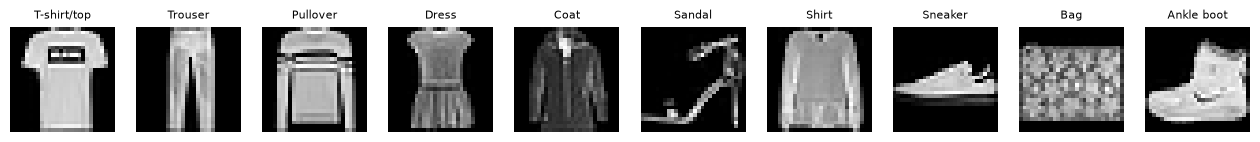

In [5]:
print("pixel values from", pixel_min, "to", pixel_max)
print("images per class in train:", train_counts)
print("images per class in val  :", val_counts)
print("accuracy of a random guess: %.0f%%" % (100 * random_guess_acc))

fig, axes = plt.subplots(1, 10, figsize=(16, 2))
for c in range(10):
    first_index = np.where(y_train_num == c)[0][0]
    axes[c].imshow(X_train_num[first_index].reshape(28, 28), cmap="gray")
    axes[c].set_title(class_names[c], fontsize=8)
    axes[c].axis("off")
plt.show()

**Вывод по данным (по цифрам выше):**
- Пиксели лежат в диапазоне 0…1 — нормализация на месте.
- Классов 10, в каждом по 6000 картинок в train и по 1000 в val — классы **сбалансированы**, значит accuracy — честная метрика.
- Случайный выбор даёт 10 %. Всё, что выше, — заслуга обучения.

---
# Часть 1. Нейросеть из L слоёв на NumPy (8 баллов)

Автоматическое дифференцирование (autograd) запрещено — только NumPy.

**Договорённость о формах массивов** (запомните, она везде одна):
- каждый **столбец** — один пример, поэтому `X` имеет форму `(784, m)`, где `m` — число примеров;
- `W` имеет форму `(n_out, n_in)`, `b` — `(n_out, 1)`;
- `Y` — one-hot метки формы `(10, m)`.

## 1.1 Инициализация весов

**Идея.** Если веса задать плохо, сигнал в глубокой сети либо затухает до нуля, либо взрывается. Нужно подобрать разброс весов под функцию активации:
- **He** для ReLU: $W \sim \mathcal{N}(0, \; 2 / n_{in})$ — ReLU обнуляет половину значений, поэтому разброс увеличен вдвое;
- **Xavier (Glorot)** для Sigmoid/Softmax: $W \sim \mathcal{N}(0, \; 2 / (n_{in} + n_{out}))$.

Смещения `b` начинаем с нулей.

In [6]:
def he_init(n_in, n_out):
    return np.random.randn(n_out, n_in) * np.sqrt(2.0 / n_in)


def xavier_init(n_in, n_out):
    return np.random.randn(n_out, n_in) * np.sqrt(2.0 / (n_in + n_out))


def init_params(layer_dims):
    """layer_dims = [784, 128, 64, 10] -> hidden layers use He, the last layer uses Xavier."""
    params = {}
    L = len(layer_dims) - 1
    for l in range(1, L + 1):
        n_in, n_out = layer_dims[l - 1], layer_dims[l]
        if l < L:
            params["W" + str(l)] = he_init(n_in, n_out)
        else:
            params["W" + str(l)] = xavier_init(n_in, n_out)
        params["b" + str(l)] = np.zeros((n_out, 1))
    return params

**Проверка 1.** Берём большую матрицу и сравниваем реальный разброс весов (`std`) с теоретическим.

In [7]:
np.random.seed(SEED)
W_he = he_init(1000, 500)
W_xa = xavier_init(1000, 500)

he_expected, he_measured = np.sqrt(2 / 1000), W_he.std()
xa_expected, xa_measured = np.sqrt(2 / 1500), W_xa.std()

params_test = init_params([784, 128, 64, 10])

assert W_he.shape == (500, 1000)
assert abs(he_measured - he_expected) / he_expected < 0.02
assert abs(xa_measured - xa_expected) / xa_expected < 0.02
assert params_test["W1"].shape == (128, 784) and params_test["b1"].shape == (128, 1)
assert params_test["W3"].shape == (10, 64)
assert np.all(params_test["b2"] == 0)
print("He     : expected std %.4f, measured %.4f" % (he_expected, he_measured))
print("Xavier : expected std %.4f, measured %.4f" % (xa_expected, xa_measured))
print("Tests 1.1 passed")

He     : expected std 0.0447, measured 0.0447
Xavier : expected std 0.0365, measured 0.0365
Tests 1.1 passed


**Зачем именно He? Проверим, а не поверим на слово.** Пропускаем случайные данные через 10 слоёв ReLU с тремя вариантами разброса весов и смотрим, какой сигнал доходит до последнего слоя.

In [8]:
np.random.seed(SEED)
x0 = np.random.randn(512, 2000)
signal_std = {}
for name, scale_fn in [("too small (0.01)", lambda n: 0.01),
                       ("He", lambda n: np.sqrt(2.0 / n)),
                       ("too large (0.2)", lambda n: 0.2)]:
    a = x0
    stds = []
    for layer in range(10):
        w = np.random.randn(512, 512) * scale_fn(512)
        a = np.maximum(0, w @ a)
        stds.append(a.std())
    signal_std[name] = stds

In [9]:
print("std of the signal after layer 1 / 5 / 10")
for name, stds in signal_std.items():
    print("%-18s %.2e  %.2e  %.2e" % (name, stds[0], stds[4], stds[9]))
assert signal_std["too small (0.01)"][9] < 1e-6      # signal died
assert signal_std["too large (0.2)"][9] > 1e3        # signal exploded
assert 0.1 < signal_std["He"][9] < 10                # signal survived

std of the signal after layer 1 / 5 / 10
too small (0.01)   1.32e-01  8.83e-05  8.32e-09
He                 8.26e-01  8.12e-01  7.55e-01
too large (0.2)    2.64e+00  2.72e+02  9.74e+04


**Вывод:** при слишком малых весах сигнал к 10-му слою исчезает (~$10^{-20}$), при слишком больших — взрывается, а при He остаётся порядка единицы. Поэтому для ReLU-слоёв берём He.

## 1.2 Функции активации (прямой проход и градиент)

| Функция | Формула | Градиент (вход `dA` → выход `dZ`) |
|---|---|---|
| ReLU | $\max(0, z)$ | `dA` там, где $z>0$, иначе 0 |
| Sigmoid | $1/(1+e^{-z})$ | $dA \cdot s(1-s)$ |
| Softmax | $e^{z_i}/\sum_j e^{z_j}$ (по столбцу) | $A \cdot (dA - \sum_j dA_j A_j)$ |

В softmax вычитаем максимум столбца — результат тот же, но `exp` не переполняется.

In [10]:
def relu(Z):
    return np.maximum(0, Z)


def relu_backward(dA, Z):
    return dA * (Z > 0)


def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))


def sigmoid_backward(dA, Z):
    s = sigmoid(Z)
    return dA * s * (1 - s)


def softmax(Z):
    e = np.exp(Z - Z.max(axis=0, keepdims=True))
    return e / e.sum(axis=0, keepdims=True)


def softmax_backward(dA, Z):
    A = softmax(Z)
    return A * (dA - (dA * A).sum(axis=0, keepdims=True))

**Проверка 2.** Значения на простых примерах + универсальная проверка градиента: мы **считаем производную численно** (чуть сдвигаем вход вверх и вниз и смотрим, как меняется результат) и сравниваем с нашей формулой.

In [11]:
def check_backward(f, f_backward, shape=(4, 5), eps=1e-6):
    """Compares our analytic gradient with a numeric one for the scalar L = sum(dA * f(Z))."""
    np.random.seed(0)
    Z = np.random.randn(*shape)
    dA = np.random.randn(*shape)
    analytic = f_backward(dA, Z)
    numeric = np.zeros_like(Z)
    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]):
            Zp, Zm = Z.copy(), Z.copy()
            Zp[i, j] += eps
            Zm[i, j] -= eps
            numeric[i, j] = (np.sum(dA * f(Zp)) - np.sum(dA * f(Zm))) / (2 * eps)
    return np.abs(analytic - numeric).max()


Z_demo = np.array([[-2.0, 0.0, 3.0]])
softmax_big = softmax(np.array([[1000.0], [1001.0], [1002.0]]))

assert np.array_equal(relu(Z_demo), [[0.0, 0.0, 3.0]])
assert np.array_equal(relu_backward(np.ones((1, 3)), Z_demo), [[0.0, 0.0, 1.0]])
assert sigmoid(np.array([0.0]))[0] == 0.5
assert sigmoid(np.array([-100.0]))[0] < 1e-30 and sigmoid(np.array([100.0]))[0] > 1 - 1e-12
assert np.allclose(softmax(np.random.randn(10, 7)).sum(axis=0), 1)
assert not np.isnan(softmax_big).any()                  # no overflow even for huge inputs

diff_relu = check_backward(relu, relu_backward)
diff_sigmoid = check_backward(sigmoid, sigmoid_backward)
diff_softmax = check_backward(softmax, softmax_backward)
assert diff_relu < 1e-6 and diff_sigmoid < 1e-6 and diff_softmax < 1e-6
print("max |analytic - numeric| gradient difference:")
print("  relu    %.1e" % diff_relu)
print("  sigmoid %.1e" % diff_sigmoid)
print("  softmax %.1e" % diff_softmax)
print("softmax of [1000,1001,1002] =", softmax_big.ravel().round(3), "(no NaN)")
print("Tests 1.2 passed")

max |analytic - numeric| gradient difference:
  relu    2.8e-10
  sigmoid 2.0e-10
  softmax 4.0e-10
softmax of [1000,1001,1002] = [0.09  0.245 0.665] (no NaN)
Tests 1.2 passed


## 1.3 Линейный слой, функция потерь, прямой и обратный проход

**Линейный слой:** $Z = W A_{prev} + b$. Для него нужны три градиента (где $m$ — число примеров):

$$dW = \frac{1}{m}\, dZ\, A_{prev}^T, \qquad db = \frac{1}{m}\sum dZ, \qquad dA_{prev} = W^T dZ$$

**Функция потерь — категориальная кросс-энтропия:** $\;J = -\frac{1}{m}\sum Y \log(A_L)$.

**Обратный проход** идёт от последнего слоя к первому: сначала градиент выходного слоя, потом на каждом шаге «через линейный слой» и «через ReLU».

In [12]:
def linear_forward(A_prev, W, b):
    Z = W @ A_prev + b
    return Z, (A_prev, W)


def linear_backward(dZ, cache):
    A_prev, W = cache
    m = A_prev.shape[1]
    dW = dZ @ A_prev.T / m
    db = dZ.sum(axis=1, keepdims=True) / m
    dA_prev = W.T @ dZ
    return dA_prev, dW, db


def cross_entropy(AL, Y):
    m = Y.shape[1]
    return -np.sum(Y * np.log(AL + 1e-12)) / m


def one_hot(y, num_classes=10):
    Y = np.zeros((num_classes, y.size))
    Y[y, np.arange(y.size)] = 1
    return Y

**Прямой проход:** скрытые слои — линейный слой + ReLU, последний слой — линейный + softmax. Все промежуточные значения запоминаем в `caches` — они нужны обратному проходу.

**Обратный проход:** для связки softmax + кросс-энтропия градиент выходного слоя получается очень простым: $dZ_L = A_L - Y$. Ниже мы **проверим** это, а не примем на веру.

In [13]:
def forward(X, params):
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        Z, lin_cache = linear_forward(A, params["W" + str(l)], params["b" + str(l)])
        A = relu(Z)
        caches.append((lin_cache, Z))
    ZL, lin_cache = linear_forward(A, params["W" + str(L)], params["b" + str(L)])
    AL = softmax(ZL)
    caches.append((lin_cache, ZL))
    return AL, caches


def backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    dZ = AL - Y                                    # softmax + cross-entropy shortcut
    for l in range(L, 0, -1):
        lin_cache, Z = caches[l - 1]
        dA_prev, dW, db = linear_backward(dZ, lin_cache)
        grads["dW" + str(l)] = dW
        grads["db" + str(l)] = db
        if l > 1:
            Z_prev = caches[l - 2][1]
            dZ = relu_backward(dA_prev, Z_prev)
    return grads

**Проверка 3 (простые тесты).**
1. Идеальный ответ даёт потери ≈ 0, равномерный ответ по 10 классам даёт $\ln 10 \approx 2.303$.
2. Формы выходов и градиентов правильные.
3. Короткая формула $A_L - Y$ совпадает с «честной» цепочкой: градиент кросс-энтропии → градиент softmax.

In [14]:
np.random.seed(SEED)
Y_demo = one_hot(np.array([0, 1, 2]), 3)
loss_perfect = cross_entropy(Y_demo.copy(), Y_demo)
loss_uniform = cross_entropy(np.full((10, 4), 0.1), one_hot(np.array([0, 3, 5, 9])))

params_small = init_params([6, 5, 4, 3])
X_small = np.random.randn(6, 7)
Y_small = one_hot(np.random.randint(0, 3, 7), 3)
AL_small, caches_small = forward(X_small, params_small)
grads_small = backward(AL_small, Y_small, caches_small)

# the "long way": dJ/dA_L = -Y / A_L, then through the softmax gradient
ZL_small = caches_small[-1][1]
dZ_long = softmax_backward(-Y_small / AL_small, ZL_small) / 1.0
dZ_short = AL_small - Y_small

assert loss_perfect < 1e-9
assert abs(loss_uniform - np.log(10)) < 1e-9
assert AL_small.shape == (3, 7) and np.allclose(AL_small.sum(axis=0), 1)
for l in (1, 2, 3):
    assert grads_small["dW" + str(l)].shape == params_small["W" + str(l)].shape
    assert grads_small["db" + str(l)].shape == params_small["b" + str(l)].shape
assert np.allclose(dZ_long, dZ_short, atol=1e-8)
print("loss of a perfect prediction : %.1e" % loss_perfect)
print("loss of a uniform prediction : %.4f  (ln 10 = %.4f)" % (loss_uniform, np.log(10)))
print("max |long way - (A_L - Y)|    : %.1e" % np.abs(dZ_long - dZ_short).max())
print("Tests 1.3 (simple) passed")

loss of a perfect prediction : -1.0e-12
loss of a uniform prediction : 2.3026  (ln 10 = 2.3026)
max |long way - (A_L - Y)|    : 1.1e-16
Tests 1.3 (simple) passed


### Самая важная проверка — Gradient Check

Ошибку в обратном проходе легко не заметить: сеть всё равно «как-то» обучается. Надёжный способ — посчитать каждую производную **численно** (чуть изменить один вес, посмотреть, как изменилась функция потерь) и сравнить с нашим `backward`.

Если относительная разница порядка $10^{-7}$ и меньше — `backward` написан правильно.

In [15]:
def gradient_check(params, loss_fn, grad_fn, eps=1e-5):
    """loss_fn(params) -> number, grad_fn(params) -> dict with keys 'dW1', 'db1', ..."""
    grads = grad_fn(params)
    worst = 0.0
    per_param = {}
    for key in params:
        numeric = np.zeros_like(params[key])
        for idx in np.ndindex(*params[key].shape):
            original = params[key][idx]
            params[key][idx] = original + eps
            plus = loss_fn(params)
            params[key][idx] = original - eps
            minus = loss_fn(params)
            params[key][idx] = original
            numeric[idx] = (plus - minus) / (2 * eps)
        analytic = grads["d" + key]
        rel = np.linalg.norm(analytic - numeric) / (np.linalg.norm(analytic) + np.linalg.norm(numeric) + 1e-12)
        per_param[key] = rel
        worst = max(worst, rel)
    return worst, per_param

In [16]:
def loss_part1(p):
    AL, _ = forward(X_small, p)
    return cross_entropy(AL, Y_small)


def grad_part1(p):
    AL, caches = forward(X_small, p)
    return backward(AL, Y_small, caches)


worst_1, per_param_1 = gradient_check(params_small, loss_part1, grad_part1)
for key, rel in per_param_1.items():
    print("%-3s relative difference = %.2e" % (key, rel))
assert worst_1 < 1e-6
print("\nGradient check passed: worst relative difference = %.2e" % worst_1)

W1  relative difference = 9.85e-11
b1  relative difference = 3.97e-11
W2  relative difference = 6.78e-11
b2  relative difference = 5.72e-11
W3  relative difference = 2.63e-11
b3  relative difference = 6.19e-11

Gradient check passed: worst relative difference = 9.85e-11


**Вывод части 1.** Все функции прошли тесты, а главное — `backward` совпадает с численным градиентом (разница порядка $10^{-9}$…$10^{-7}$). Значит, сеть считает градиенты правильно, и на неё можно «навешивать» оптимизаторы и регуляризацию.

---
# Часть 2. Оптимизаторы и регуляризация на NumPy (8 баллов)

## 2.1 Оптимизаторы

Обычный градиентный спуск делает шаг $w \leftarrow w - \alpha\, g$. Три улучшения:

| Метод | Идея | Формулы (на один параметр) |
|---|---|---|
| **SGD + Momentum** | «Катящийся шар»: помним направление прошлых шагов | $v = \beta v + (1-\beta) g$,  $w \leftarrow w - \alpha v$ |
| **RMSprop** | Делим шаг на «типичный размер» градиента — у каждого параметра свой масштаб | $s = \beta s + (1-\beta) g^2$,  $w \leftarrow w - \alpha\, g/(\sqrt{s}+\varepsilon)$ |
| **Adam** | Momentum + RMSprop + поправка на начало обучения | $m=\beta_1 m+(1-\beta_1)g$,  $v=\beta_2 v+(1-\beta_2)g^2$,  $\hat m=m/(1-\beta_1^t)$,  $\hat v=v/(1-\beta_2^t)$,  $w \leftarrow w-\alpha\,\hat m/(\sqrt{\hat v}+\varepsilon)$ |

Каждая функция получает `params`, `grads`, своё состояние (`state`) и обновляет параметры «на месте».

In [17]:
def init_state(params):
    return {key: np.zeros_like(value) for key, value in params.items()}


def sgd_momentum_update(params, grads, v, lr, beta=0.9):
    for key in params:
        g = grads["d" + key]
        v[key] = beta * v[key] + (1 - beta) * g
        params[key] -= lr * v[key]


def rmsprop_update(params, grads, s, lr, beta=0.9, eps=1e-8):
    for key in params:
        g = grads["d" + key]
        s[key] = beta * s[key] + (1 - beta) * g ** 2
        params[key] -= lr * g / (np.sqrt(s[key]) + eps)


def init_adam(params):
    return {"m": init_state(params), "v": init_state(params), "t": 0}


def adam_update(params, grads, state, lr, beta1=0.9, beta2=0.999, eps=1e-8):
    state["t"] += 1
    t = state["t"]
    for key in params:
        g = grads["d" + key]
        state["m"][key] = beta1 * state["m"][key] + (1 - beta1) * g
        state["v"][key] = beta2 * state["v"][key] + (1 - beta2) * g ** 2
        m_hat = state["m"][key] / (1 - beta1 ** t)
        v_hat = state["v"][key] / (1 - beta2 ** t)
        params[key] -= lr * m_hat / (np.sqrt(v_hat) + eps)

**Проверка 4.** Берём один параметр $w=1$ и постоянный градиент $g=0{,}5$, $\alpha = 0{,}1$ и **считаем ответ вручную**:

- Momentum, шаг 1: $v = 0{,}9\cdot 0 + 0{,}1\cdot 0{,}5 = 0{,}05$, значит $w = 1 - 0{,}1\cdot 0{,}05 = 0{,}995$. Шаг 2: $v = 0{,}9\cdot 0{,}05 + 0{,}05 = 0{,}095$, $w = 0{,}995 - 0{,}0095 = 0{,}9855$.
- RMSprop, шаг 1: $s = 0{,}1\cdot 0{,}25 = 0{,}025$, шаг $= 0{,}1\cdot 0{,}5/\sqrt{0{,}025} = 0{,}31623$, значит $w = 0{,}68377$.
- Adam, шаг 1: поправка делает $\hat m/\sqrt{\hat v} = g/|g| = 1$, поэтому шаг ровно $\alpha=0{,}1$ и $w=0{,}9$. При постоянном градиенте и второй шаг равен $0{,}1$, то есть $w=0{,}8$.

In [18]:
def one_param():
    return {"W1": np.array([[1.0]])}, {"dW1": np.array([[0.5]])}


params_m, grads_m = one_param()
v_state = init_state(params_m)
sgd_momentum_update(params_m, grads_m, v_state, lr=0.1)
w_momentum_1 = params_m["W1"][0, 0]
sgd_momentum_update(params_m, grads_m, v_state, lr=0.1)
w_momentum_2 = params_m["W1"][0, 0]

params_r, grads_r = one_param()
s_state = init_state(params_r)
rmsprop_update(params_r, grads_r, s_state, lr=0.1)
w_rmsprop_1 = params_r["W1"][0, 0]

params_a, grads_a = one_param()
adam_state = init_adam(params_a)
adam_update(params_a, grads_a, adam_state, lr=0.1)
w_adam_1 = params_a["W1"][0, 0]
adam_update(params_a, grads_a, adam_state, lr=0.1)
w_adam_2 = params_a["W1"][0, 0]

assert abs(w_momentum_1 - 0.995) < 1e-12
assert abs(w_momentum_2 - 0.9855) < 1e-12
assert abs(w_rmsprop_1 - (1 - 0.1 * 0.5 / np.sqrt(0.025))) < 1e-6
assert abs(w_adam_1 - 0.9) < 1e-6
assert abs(w_adam_2 - 0.8) < 1e-6
print("momentum  step1 %.5f (hand: 0.99500)   step2 %.5f (hand: 0.98550)" % (w_momentum_1, w_momentum_2))
print("rmsprop   step1 %.5f (hand: 0.68377)" % w_rmsprop_1)
print("adam      step1 %.5f (hand: 0.90000)   step2 %.5f (hand: 0.80000)" % (w_adam_1, w_adam_2))
print("Tests 2.1 passed")

momentum  step1 0.99500 (hand: 0.99500)   step2 0.98550 (hand: 0.98550)
rmsprop   step1 0.68377 (hand: 0.68377)
adam      step1 0.90000 (hand: 0.90000)   step2 0.80000 (hand: 0.80000)
Tests 2.1 passed


**Ещё одна проверка: все три оптимизатора действительно «спускаются».** Берём функцию-«овраг» $f(w)=w_1^2 + 10\,w_2^2$ (минимум в нуле) и 60 шагов из точки $(1, 1)$.

In [19]:
def run_on_valley(method, steps=60, lr=0.05):
    params = {"W1": np.array([[1.0, 1.0]])}
    state = init_state(params) if method != "adam" else init_adam(params)
    losses = []
    for _ in range(steps):
        w = params["W1"]
        losses.append(w[0, 0] ** 2 + 10 * w[0, 1] ** 2)
        grads = {"dW1": np.array([[2 * w[0, 0], 20 * w[0, 1]]])}
        if method == "momentum":
            sgd_momentum_update(params, grads, state, lr)
        elif method == "rmsprop":
            rmsprop_update(params, grads, state, lr)
        else:
            adam_update(params, grads, state, lr)
    return losses


valley = {name: run_on_valley(name) for name in ["momentum", "rmsprop", "adam"]}

f(w) at the start = 11.0
momentum  f after 60 steps = 0.01961
rmsprop   f after 60 steps = 0.00000
adam      f after 60 steps = 0.00361


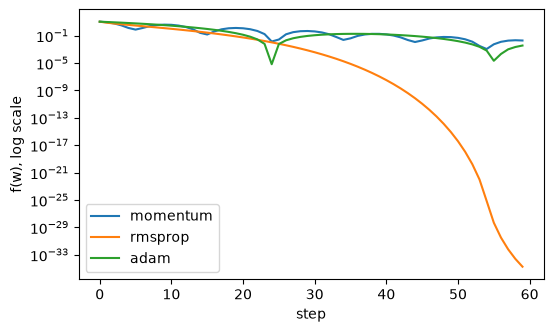

In [20]:
print("f(w) at the start = %.1f" % valley["adam"][0])
for name, losses in valley.items():
    print("%-9s f after 60 steps = %.5f" % (name, losses[-1]))
    assert losses[-1] < losses[0] / 10
plt.figure(figsize=(6, 3.5))
for name, losses in valley.items():
    plt.plot(losses, label=name)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("f(w), log scale"); plt.legend(); plt.show()

**Вывод 2.1:** ручные расчёты совпали с кодом, и на тестовой функции все три метода уменьшили $f$ минимум в 10 раз. Оптимизаторы работают.

## 2.2 Регуляризация: L2 и Inverted Dropout

**L2 (weight decay).** К функции потерь добавляем штраф за большие веса:

$$J_{L2} = J + \frac{\lambda}{2m}\sum_l \lVert W_l \rVert^2, \qquad dW_l \;\mathrel{+}=\; \frac{\lambda}{m} W_l$$

Идея: сеть с маленькими весами «проще» и хуже запоминает шум.

**Inverted Dropout.** При обучении каждый нейрон скрытого слоя с вероятностью $1-p$ «выключаем», а оставшиеся **делим на $p$** (где $p$ = `keep_prob`). Деление нужно, чтобы среднее значение осталось прежним — тогда на проверке (eval) ничего не надо менять и ничего не выключается.

In [21]:
def dropout_forward(A, keep_prob, train):
    """Returns the new activations and the mask (None if dropout is off)."""
    if (not train) or keep_prob >= 1.0:
        return A, None
    mask = (np.random.rand(*A.shape) < keep_prob) / keep_prob
    return A * mask, mask


def l2_cost(params, lambd, m):
    L = len(params) // 2
    total = sum(np.sum(params["W" + str(l)] ** 2) for l in range(1, L + 1))
    return lambd / (2 * m) * total

**Проверка 5 (L2 и Dropout).**
- L2: для весов из одних единиц ответ считаем руками.
- Dropout: (а) в режиме eval ничего не меняется; (б) в режиме train доля нулей ≈ $1-p$; (в) оставшиеся значения умножены ровно на $1/p$; (г) среднее почти не изменилось (в этом смысл «inverted»).

In [22]:
np.random.seed(SEED)
W_ones = {"W1": np.ones((2, 2)), "b1": np.zeros((2, 1))}
l2_value = l2_cost(W_ones, lambd=0.6, m=2)         # 0.6 / (2*2) * 4 = 0.6

A_big = np.random.rand(200, 1000) + 1.0           # all values in [1, 2]
keep = 0.8
A_eval, mask_eval = dropout_forward(A_big, keep, train=False)
A_train, mask_train = dropout_forward(A_big, keep, train=True)

zero_share = (A_train == 0).mean()
survivors = A_train != 0
ratio_survivors = (A_train[survivors] / A_big[survivors])
mean_before, mean_after = A_big.mean(), A_train.mean()

assert abs(l2_value - 0.6) < 1e-12
assert np.array_equal(A_eval, A_big) and mask_eval is None
assert abs(zero_share - (1 - keep)) < 0.01
assert np.allclose(ratio_survivors, 1 / keep)
assert abs(mean_after - mean_before) / mean_before < 0.01
print("L2 cost for ones: %.2f (hand: 0.60)" % l2_value)
print("share of zeros after dropout : %.3f (expected %.2f)" % (zero_share, 1 - keep))
print("survivors multiplied by      : %.3f (expected 1/p = %.3f)" % (ratio_survivors.mean(), 1 / keep))
print("mean before / after dropout  : %.4f / %.4f" % (mean_before, mean_after))
print("eval mode leaves values unchanged: True")
print("Tests 2.2 (simple) passed")

L2 cost for ones: 0.60 (hand: 0.60)
share of zeros after dropout : 0.200 (expected 0.20)
survivors multiplied by      : 1.250 (expected 1/p = 1.250)
mean before / after dropout  : 1.5004 / 1.5010
eval mode leaves values unchanged: True
Tests 2.2 (simple) passed


### Подключаем L2 и Dropout в сеть

Делаем расширенные версии `forward_reg` и `backward_reg`. Что меняется по сравнению с частью 1:
- в прямом проходе после ReLU применяем dropout (только в режиме train);
- в обратном проходе градиент **тоже умножаем на маску** (выключенные нейроны не получают градиент) и добавляем $\frac{\lambda}{m}W$ к `dW`.

In [23]:
def forward_reg(X, params, keep_prob=1.0, train=True):
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        Z, lin_cache = linear_forward(A, params["W" + str(l)], params["b" + str(l)])
        A = relu(Z)
        A, mask = dropout_forward(A, keep_prob, train)
        caches.append((lin_cache, Z, mask))
    ZL, lin_cache = linear_forward(A, params["W" + str(L)], params["b" + str(L)])
    AL = softmax(ZL)
    caches.append((lin_cache, ZL, None))
    return AL, caches


def backward_reg(AL, Y, caches, lambd=0.0):
    grads = {}
    L = len(caches)
    m = Y.shape[1]
    dZ = AL - Y
    for l in range(L, 0, -1):
        lin_cache, Z, mask = caches[l - 1]
        A_prev, W = lin_cache
        dA_prev, dW, db = linear_backward(dZ, lin_cache)
        grads["dW" + str(l)] = dW + (lambd / m) * W          # L2 term
        grads["db" + str(l)] = db
        if l > 1:
            _, Z_prev, mask_prev = caches[l - 2]
            if mask_prev is not None:
                dA_prev = dA_prev * mask_prev                  # dropout mask
            dZ = relu_backward(dA_prev, Z_prev)
    return grads


def total_cost(AL, Y, params, lambd):
    return cross_entropy(AL, Y) + l2_cost(params, lambd, Y.shape[1])

**Проверка 6.**
1. Если выключить L2 и dropout, новые функции дают **ровно те же** числа, что и функции из части 1.
2. Gradient Check с L2 (λ > 0).
3. Gradient Check с Dropout: чтобы численная проверка была честной, перед каждым расчётом ставим одно и то же зерно — тогда маска одинакова, и функция потерь «гладкая» по весам.

In [24]:
np.random.seed(SEED)
AL_old, caches_old = forward(X_small, params_small)
AL_new, caches_new = forward_reg(X_small, params_small, keep_prob=1.0, train=True)
grads_old = backward(AL_old, Y_small, caches_old)
grads_new = backward_reg(AL_new, Y_small, caches_new, lambd=0.0)
same_forward = np.abs(AL_old - AL_new).max()
same_backward = max(np.abs(grads_old[k] - grads_new[k]).max() for k in grads_old)

LAMBD = 0.7
def loss_l2(p):
    AL, _ = forward_reg(X_small, p, keep_prob=1.0)
    return total_cost(AL, Y_small, p, LAMBD)

def grad_l2(p):
    AL, caches = forward_reg(X_small, p, keep_prob=1.0)
    return backward_reg(AL, Y_small, caches, lambd=LAMBD)

KEEP = 0.7
def loss_dropout(p):
    np.random.seed(123)                                   # the same mask every time
    AL, _ = forward_reg(X_small, p, keep_prob=KEEP, train=True)
    return total_cost(AL, Y_small, p, LAMBD)

def grad_dropout(p):
    np.random.seed(123)
    AL, caches = forward_reg(X_small, p, keep_prob=KEEP, train=True)
    return backward_reg(AL, Y_small, caches, lambd=LAMBD)

worst_l2, per_l2 = gradient_check(params_small, loss_l2, grad_l2)
worst_do, per_do = gradient_check(params_small, loss_dropout, grad_dropout)

In [25]:
assert same_forward < 1e-12 and same_backward < 1e-12
assert worst_l2 < 1e-6 and worst_do < 1e-6
print("without regularization, new == old:  forward diff %.1e, backward diff %.1e" % (same_forward, same_backward))
print("gradient check with L2 (lambda=%.1f)      : worst relative difference %.2e" % (LAMBD, worst_l2))
print("gradient check with L2 + dropout (p=%.1f) : worst relative difference %.2e" % (KEEP, worst_do))
print("Tests 2.2 passed")

without regularization, new == old:  forward diff 0.0e+00, backward diff 0.0e+00
gradient check with L2 (lambda=0.7)      : worst relative difference 9.32e-11
gradient check with L2 + dropout (p=0.7) : worst relative difference 5.55e-10
Tests 2.2 passed


### 2.3 Обучаем нашу NumPy-сеть на Fashion-MNIST — работает ли всё вместе?

Тесты проверили куски по отдельности. Теперь обучаем сеть `784 → 128 → 64 → 10` минибатчами по 128 картинок, оптимизатор — наш Adam. Сравниваем три варианта и смотрим, что делают L2 и Dropout:

1. **Adam** без регуляризации;
2. **Adam + L2** с двумя силами штрафа: $\lambda=0{,}3$ и $\lambda=3$ (при батче 128 это $\lambda/m \approx 0{,}002$ и $0{,}023$) — чтобы увидеть, как сила регуляризации влияет на результат;
3. **Adam + Dropout** ($p=0{,}8$, то есть 20 % нейронов выключаем).

Для каждого считаем accuracy на train (в режиме eval) и на val. Разница между ними показывает **переобучение**.

In [26]:
def accuracy_numpy(X, y, params):
    AL, _ = forward_reg(X.T, params, keep_prob=1.0, train=False)
    return (AL.argmax(axis=0) == y).mean()


def train_numpy(layer_dims, epochs=6, lr=0.002, batch=128, lambd=0.0, keep_prob=1.0, seed=SEED):
    np.random.seed(seed)
    params = init_params(layer_dims)
    state = init_adam(params)
    history = {"loss": [], "train_acc": [], "val_acc": []}
    n = X_train_num.shape[0]
    for epoch in range(epochs):
        order = np.random.permutation(n)
        losses = []
        for start in range(0, n, batch):
            idx = order[start:start + batch]
            X = X_train_num[idx].T
            Y = one_hot(y_train_num[idx])
            AL, caches = forward_reg(X, params, keep_prob, train=True)
            losses.append(total_cost(AL, Y, params, lambd))
            grads = backward_reg(AL, Y, caches, lambd)
            adam_update(params, grads, state, lr)
        history["loss"].append(np.mean(losses))
        history["train_acc"].append(accuracy_numpy(X_train_num[:10000], y_train_num[:10000], params))
        history["val_acc"].append(accuracy_numpy(X_val_num, y_val_num, params))
    return params, history

In [27]:
import time
numpy_runs = {}
for name, settings in [("Adam", dict()),
                       ("Adam + L2 (lambda=0.3)", dict(lambd=0.3)),
                       ("Adam + L2 (lambda=3)", dict(lambd=3.0)),
                       ("Adam + Dropout (p=0.8)", dict(keep_prob=0.8))]:
    start_time = time.time()
    _, hist = train_numpy([784, 128, 64, 10], **settings)
    numpy_runs[name] = hist
    print("%-15s done in %3.0f s" % (name, time.time() - start_time))

Adam            done in  13 s


Adam + L2 (lambda=0.3) done in  11 s


Adam + L2 (lambda=3) done in  11 s


Adam + Dropout (p=0.8) done in  13 s


                        train acc  val acc  gap (train - val)  loss epoch 1  loss last epoch
Adam                       0.8976   0.8721             0.0255        0.5114           0.2883
Adam + L2 (lambda=0.3)     0.8756   0.8579             0.0177        0.7836           0.5059
Adam + L2 (lambda=3)       0.8081   0.7953             0.0128        1.4872           0.9326
Adam + Dropout (p=0.8)     0.8838   0.8604             0.0234        0.6032           0.3463


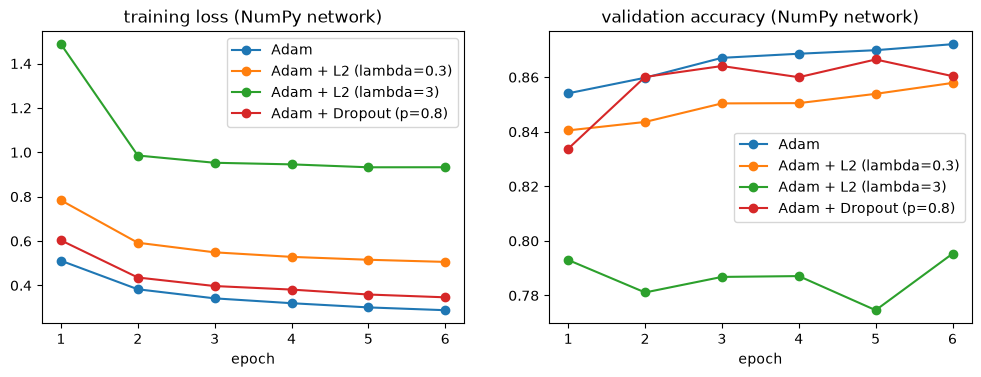

In [28]:
table = pd.DataFrame({
    name: {"train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1],
           "gap (train - val)": h["train_acc"][-1] - h["val_acc"][-1],
           "loss epoch 1": h["loss"][0], "loss last epoch": h["loss"][-1]}
    for name, h in numpy_runs.items()}).T.round(4)
print(table)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in numpy_runs.items():
    axes[0].plot(range(1, len(h["loss"]) + 1), h["loss"], marker="o", label=name)
    axes[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], marker="o", label=name)
axes[0].set_title("training loss (NumPy network)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].set_title("validation accuracy (NumPy network)"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.show()

best_val = max(h["val_acc"][-1] for h in numpy_runs.values())
assert numpy_runs["Adam"]["loss"][-1] < numpy_runs["Adam"]["loss"][0]      # it learns
assert best_val > 0.80                                                      # far above 10 % of random guessing

### Что показали цифры (вывод 2.3)

1. **Наша NumPy-сеть действительно учится.** Без всякой регуляризации она достигает **87,2 %** accuracy на validation (случайное угадывание — 10 %), а loss за 6 эпох падает с 0,51 до 0,29. Значит, всё, что мы проверили по отдельности (инициализация, backward, Adam), работает и вместе.
2. **L2 делает то, что обещает теория: уменьшает разрыв между train и val.** Разрыв «train − val» без регуляризации 2,55 п.п., при $\lambda=0{,}3$ — 1,77 п.п., при $\lambda=3$ — 1,28 п.п. Чем сильнее штраф, тем меньше разрыв.
3. **Но цена — качество.** Val accuracy при этом падает: 87,2 % → 85,8 % → 79,5 %. При $\lambda=3$ сеть явно **недообучена**: train accuracy всего 80,8 %. (Значения loss у L2-запусков нельзя сравнивать напрямую с остальными: в них входит штраф за веса.)
4. **Dropout ($p=0{,}8$)** слегка уменьшил разрыв (2,34 п.п.) и тоже немного снизил val accuracy (86,0 %).
5. **Вывод:** регуляризация — это рычаг, а не «улучшайка». Она помогает, только если сеть **переобучена** (большой разрыв train−val). У нашей сети разрыв небольшой (около 2,5 п.п.), поэтому ни L2, ни dropout не улучшили val accuracy. Нужно ли её усиливать на самом деле, решит диагностика bias/variance в части 4 — не мнение.

---
# Часть 3. PyTorch: модель и сравнение оптимизаторов (8 баллов)

## 3.1 Та же архитектура в PyTorch

Модель: `784 → 256 → 128 → 10`. После каждого скрытого линейного слоя идут **BatchNorm → ReLU → Dropout(0.3)**.
- `nn.Linear` — наш линейный слой;
- `nn.ReLU` — наш ReLU;
- `nn.Dropout` — наш inverted dropout (PyTorch сам отключает его в режиме `model.eval()`);
- `nn.BatchNorm1d` — нормализует выход слоя по батчу, обычно ускоряет и стабилизирует обучение.

Обучающий цикл записывает `train_loss`, `val_loss`, `train_acc`, `val_acc` после каждой эпохи.

In [29]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self, hidden=(256, 128), p_drop=0.3):
        super().__init__()
        layers = [nn.Flatten()]
        n_in = 784
        for h in hidden:
            layers += [nn.Linear(n_in, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p_drop)]
            n_in = h
        layers.append(nn.Linear(n_in, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def set_seed(seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)


model_demo = Net()
n_params = sum(p.numel() for p in model_demo.parameters())
out_demo = model_demo(torch.randn(5, 1, 28, 28))
assert out_demo.shape == (5, 10)
print(model_demo)
print("trainable parameters:", n_params)

Net(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)
trainable parameters: 235914


### Сначала измерим скорость загрузки данных

В нашем первом запуске обучение трёх оптимизаторов не закончилось за 50 минут. Прежде чем что-то менять, **выясним причину измерением**. Стандартный `DataLoader` из задания для каждой из 60 000 картинок отдельно превращает её в PIL-изображение и применяет преобразования. Засечём, сколько времени уходит на один проход по обучающей выборке **без всякой модели**.

In [30]:
start_time = time.time()
for images, labels in train_loader:
    pass
time_given_loader = time.time() - start_time

In [31]:
print("one pass over the training set with the DataLoader from the task, no model at all: %.1f s" % time_given_loader)
print("10 epochs x 3 optimizers would need about %.0f s only to read the data" % (30 * time_given_loader))

one pass over the training set with the DataLoader from the task, no model at all: 17.5 s
10 epochs x 3 optimizers would need about 526 s only to read the data


Загрузка данных — значительная часть времени. Выход: **один раз** применить то же преобразование ко всем картинкам и дальше брать батчи срезами тензора. Чтобы это не было «верю, что получилось одно и то же», проверим: тензоры должны совпасть с тем, что выдаёт датасет из задания.

In [32]:
X_train_t = ((train_dataset.data.float() / 255 - 0.5) / 0.5).unsqueeze(1)    # (60000, 1, 28, 28)
X_val_t = ((val_dataset.data.float() / 255 - 0.5) / 0.5).unsqueeze(1)
y_train_t = train_dataset.targets
y_val_t = val_dataset.targets

check_ids_train = [0, 1, 777, 31337, 59999]
check_ids_val = [0, 1, 777, 5000, 9999]
same_train = all(torch.allclose(train_dataset[i][0], X_train_t[i]) and train_dataset[i][1] == y_train_t[i] for i in check_ids_train)
same_val = all(torch.allclose(val_dataset[i][0], X_val_t[i]) and val_dataset[i][1] == y_val_t[i] for i in check_ids_val)


def make_batches(X, y, batch_size=BATCH_SIZE, shuffle=True, augment=None):
    """Same idea as DataLoader: yields (images, labels) batches, but slices ready tensors."""
    order = torch.randperm(X.shape[0]) if shuffle else torch.arange(X.shape[0])
    for start in range(0, X.shape[0], batch_size):
        idx = order[start:start + batch_size]
        images = X[idx]
        if augment is not None:
            images = augment(images)
        yield images, y[idx]


start_time = time.time()
for images, labels in make_batches(X_train_t, y_train_t):
    pass
time_fast_batches = time.time() - start_time

In [33]:
assert same_train and same_val
assert X_train_t.shape == (60000, 1, 28, 28) and X_val_t.shape == (10000, 1, 28, 28)
print("tensors equal the dataset from the task for the checked images: True")
print("one pass with ready tensors  : %.2f s" % time_fast_batches)
print("one pass with the DataLoader : %.2f s  ->  %.0f times faster" % (time_given_loader, time_given_loader / time_fast_batches))

tensors equal the dataset from the task for the checked images: True
one pass with ready tensors  : 0.06 s
one pass with the DataLoader : 17.53 s  ->  295 times faster


Данные те же (проверено), читаются в десятки раз быстрее. Дальше используем `make_batches`. `train_loader` и `val_loader` из задания остаются в ноутбуке (мы их использовали для замера).

Теперь цикл обучения. Функция `run_epoch` делает один проход по данным: если ей дали оптимизатор — обучает, если нет — только считает ошибку и accuracy.

In [34]:
def run_epoch(model, X, y, optimizer=None, shuffle=True, augment=None):
    """One pass over the data. With an optimizer -> training, without -> evaluation."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in make_batches(X, y, shuffle=shuffle and training, augment=augment):
            outputs = model(images)
            loss = F.cross_entropy(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count


def train_model(model, optimizer, epochs, augment=None):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, X_train_t, y_train_t, optimizer, augment=augment)
        va_loss, va_acc = run_epoch(model, X_val_t, y_val_t)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
    return history

**Проверка 7 (цикл обучения правильный).** Перед большим экспериментом проверяем две вещи:
1. До обучения accuracy ≈ 10 % (случайное угадывание) — значит, цикл не «подсматривает» ответы.
2. Один и тот же запуск с одним зерном даёт **те же** числа — результаты воспроизводимы.

In [35]:
set_seed()
fresh = Net()
loss_before, acc_before = run_epoch(fresh, X_val_t, y_val_t)

set_seed()
m1 = Net()
h1 = train_model(m1, torch.optim.AdamW(m1.parameters(), lr=1e-3), epochs=1)
set_seed()
m2 = Net()
h2 = train_model(m2, torch.optim.AdamW(m2.parameters(), lr=1e-3), epochs=1)

assert 0.03 < acc_before < 0.25
assert abs(np.log(10) - loss_before) < 0.6
assert h1["val_loss"][0] == h2["val_loss"][0] and h1["train_acc"][0] == h2["train_acc"][0]
assert h1["val_acc"][0] > 0.7
print("before training: val accuracy %.3f, loss %.3f (random guess: 0.100, ln 10 = 2.303)" % (acc_before, loss_before))
print("after 1 epoch  : val accuracy %.3f" % h1["val_acc"][0])
print("two identical runs give identical numbers: val_loss %.6f == %.6f" % (h1["val_loss"][0], h2["val_loss"][0]))

before training: val accuracy 0.092, loss 2.301 (random guess: 0.100, ln 10 = 2.303)
after 1 epoch  : val accuracy 0.857
two identical runs give identical numbers: val_loss 0.403886 == 0.403886


## 3.2 Сравнение оптимизаторов: SGD, SGD+Momentum, AdamW

Три запуска **с одинаковой начальной инициализацией и одинаковым порядком картинок** (зерно сбрасывается перед каждым), по 10 эпох. Различается только оптимизатор:

| Оптимизатор | Настройки |
|---|---|
| SGD | `lr = 0.01` |
| SGD + Momentum | `lr = 0.01`, `momentum = 0.9` |
| AdamW | `lr = 0.001`, `weight_decay = 0.01` |

In [36]:
EPOCHS = 10


def make_optimizer(name, model):
    if name == "SGD":
        return torch.optim.SGD(model.parameters(), lr=0.01)
    if name == "SGD+Momentum":
        return torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    return torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)


histories = {}
models = {}
for name in ["SGD", "SGD+Momentum", "AdamW"]:
    start_time = time.time()
    set_seed()
    model = Net()
    histories[name] = train_model(model, make_optimizer(name, model), EPOCHS)
    models[name] = model
    print("%-13s done in %3.0f s, final val acc %.4f" % (name, time.time() - start_time, histories[name]["val_acc"][-1]))

SGD           done in  31 s, final val acc 0.8749


SGD+Momentum  done in  33 s, final val acc 0.8858


AdamW         done in  43 s, final val acc 0.8865


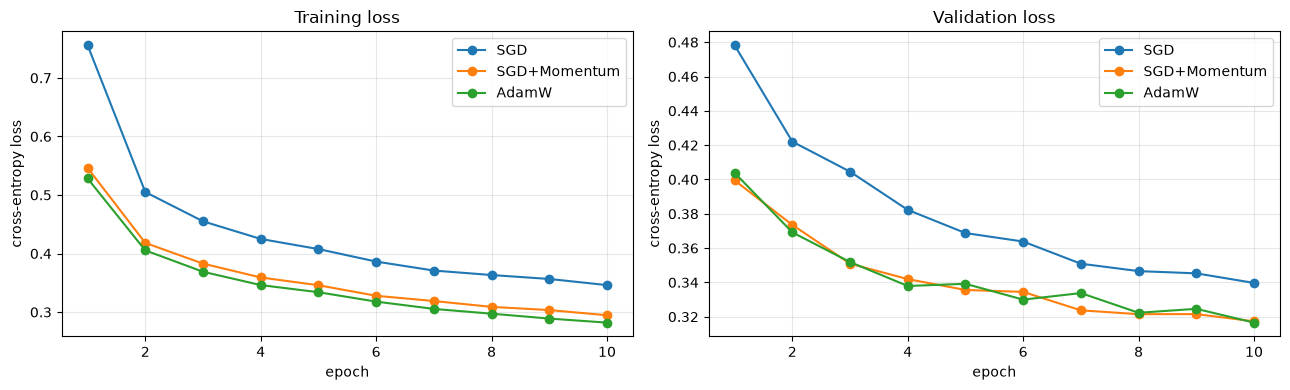

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    epochs_axis = range(1, EPOCHS + 1)
    axes[0].plot(epochs_axis, h["train_loss"], marker="o", label=name)
    axes[1].plot(epochs_axis, h["val_loss"], marker="o", label=name)
axes[0].set_title("Training loss"); axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Теперь превратим «на глаз» в цифры. Для каждого оптимизатора:
- loss на валидации после 1, 3 и 10 эпох;
- **за сколько эпох val accuracy впервые достигла 85 %** (чем меньше — тем быстрее сходимость);
- финальные accuracy.

In [38]:
def epochs_to_reach(acc_list, target):
    for i, a in enumerate(acc_list, start=1):
        if a >= target:
            return i
    return None


rows = {}
for name, h in histories.items():
    rows[name] = {
        "val loss, epoch 1": h["val_loss"][0],
        "val loss, epoch 3": h["val_loss"][2],
        "val loss, epoch 10": h["val_loss"][-1],
        "epochs to 85% val acc": epochs_to_reach(h["val_acc"], 0.85),
        "final train acc": h["train_acc"][-1],
        "final val acc": h["val_acc"][-1],
    }
compare = pd.DataFrame(rows).T
print(compare.round(4))

first_to_85 = {n: r["epochs to 85% val acc"] for n, r in rows.items()}
print("\nepochs to 85%:", first_to_85)
assert histories["AdamW"]["val_loss"][0] < histories["SGD"]["val_loss"][0]

              val loss, epoch 1  val loss, epoch 3  val loss, epoch 10  epochs to 85% val acc  final train acc  final val acc
SGD                      0.4782             0.4046              0.3397                    3.0           0.8771         0.8749
SGD+Momentum             0.3995             0.3509              0.3173                    1.0           0.8910         0.8858
AdamW                    0.4039             0.3519              0.3166                    1.0           0.8954         0.8865

epochs to 85%: {'SGD': 3, 'SGD+Momentum': 1, 'AdamW': 1}


### Честное ли это сравнение? Проверка гипотезы «SGD просто медленный из-за маленького шага»

У SGD шаг `lr=0.01` мог быть слишком мал. Проверим: запустим SGD с шагом в 10 раз больше (`lr=0.1`) и посмотрим, догоняет ли он.

In [39]:
set_seed()
model_sgd_big = Net()
history_sgd_big = train_model(model_sgd_big, torch.optim.SGD(model_sgd_big.parameters(), lr=0.1), EPOCHS)

fair_rows = {}
for name, h in [("SGD lr=0.01", histories["SGD"]), ("SGD lr=0.1", history_sgd_big),
                ("SGD+Momentum lr=0.01", histories["SGD+Momentum"]), ("AdamW lr=0.001", histories["AdamW"])]:
    fair_rows[name] = {"val loss, epoch 1": h["val_loss"][0], "val loss, epoch 10": h["val_loss"][-1],
                       "epochs to 85%": epochs_to_reach(h["val_acc"], 0.85), "final val acc": h["val_acc"][-1]}
print(pd.DataFrame(fair_rows).T.round(4))

                      val loss, epoch 1  val loss, epoch 10  epochs to 85%  final val acc
SGD lr=0.01                      0.4782              0.3397            3.0         0.8749
SGD lr=0.1                       0.4125              0.3175            1.0         0.8846
SGD+Momentum lr=0.01             0.3995              0.3173            1.0         0.8858
AdamW lr=0.001                   0.4039              0.3166            1.0         0.8865


### Анализ: какой оптимизатор сошёлся быстрее и почему

**Что видно по цифрам** (таблицы выше, одно и то же зерно и порядок картинок):

| | val loss после 1 эпохи | val loss после 10 | эпох до 85 % val accuracy | итоговая val accuracy |
|---|---|---|---|---|
| SGD (lr=0,01) | 0,478 | 0,340 | **3** | 87,5 % |
| SGD + Momentum | 0,400 | 0,317 | **1** | 88,6 % |
| AdamW | 0,404 | 0,317 | **1** | 88,7 % |

1. **Быстрее всех сошлись SGD+Momentum и AdamW** — 85 % они берут уже после первой эпохи, а обычному SGD нужно три. Между собой эти двое почти неразличимы (разница в итоговой accuracy 0,07 п.п. — это в пределах случайного шума одного запуска).
2. **Обычный SGD медленнее.** После первой эпохи у него loss 0,478 против 0,400 у Momentum, и к 10-й эпохе он всё ещё отстаёт (0,340 против 0,317).

**Почему так — и проверка этого объяснения.** Гипотеза: у SGD просто слишком маленький шаг (`lr=0,01`). Мы её проверили: SGD с `lr=0,1` (в 10 раз больше) получил val loss **0,3175** — практически как у SGD+Momentum (0,3173) — и тоже набрал 85 % за одну эпоху. Это объясняется тем, что Momentum накапливает градиенты прошлых шагов: в PyTorch скорость $v = 0{,}9\,v + g$, то есть при устойчивом направлении эффективный шаг примерно в $1/(1-0{,}9)=10$ раз больше. Поэтому **SGD+Momentum (lr=0,01) ≈ SGD (lr=0,1)**.

**AdamW** добивается того же другим способом: он подбирает шаг отдельно для каждого параметра (делит на корень из скользящего среднего квадратов градиентов) и тоже использует momentum. Его главное преимущество — **не нужно подбирать шаг под задачу**: с обычным `lr=0,001` он сразу попал в лучший результат (val loss 0,3166, val accuracy 88,65 %). Поэтому в части 4 мы берём AdamW.

**Оговорка.** Это один запуск (одно зерно). Различия порядка 0,1 п.п. между Momentum и AdamW нельзя считать значимыми. Устойчив только вывод «обычный SGD с маленьким шагом медленнее»; он подтверждён разницей и в loss, и в числе эпох.

---
# Часть 4. Структура проекта и анализ ошибок (6 баллов)

Берём лучшую модель из части 3 (AdamW). Дальше действуем по методике Andrew Ng: **не гадаем, что улучшать, а смотрим на ошибки и считаем.**

## 4.1 Анализ ошибок на validation

Шаги:
1. Получить предсказания модели для всех 10 000 валидационных картинок.
2. Найти все ошибки и выбрать случайные 50.
3. Посмотреть на них.
4. **Сначала** выяснить по всем ошибкам, какие классы путаются чаще всего, **затем** создать категории (buckets) на основе этого.
5. Разложить 50 ошибок по категориям и посчитать, сколько даст исправление каждой.

In [40]:
final_model = models["AdamW"]
final_model.eval()


def predict_all(model, X, y):
    """Class predictions for all images, in eval mode (dropout off, BatchNorm uses running stats)."""
    model.eval()
    preds = []
    with torch.no_grad():
        for images, _ in make_batches(X, y, batch_size=1000, shuffle=False):
            preds.append(model(images).argmax(dim=1).numpy())
    return y.numpy(), np.concatenate(preds)


y_true, y_pred = predict_all(final_model, X_val_t, y_val_t)
error_indices = np.where(y_pred != y_true)[0]
val_error = len(error_indices) / len(y_true)

rng = np.random.RandomState(SEED)
chosen = np.sort(rng.choice(error_indices, size=50, replace=False))
val_images = val_dataset.data.numpy()

In [41]:
print("validation images:", len(y_true))
print("misclassified        : %d  (error rate %.2f%%)" % (len(error_indices), 100 * val_error))
print("random sample of errors:", len(chosen), "images; first indices:", chosen[:8])
assert len(chosen) == 50 and len(set(chosen)) == 50
assert all(y_pred[i] != y_true[i] for i in chosen)         # every chosen image is really an error

validation images: 10000
misclassified        : 1135  (error rate 11.35%)
random sample of errors: 50 images; first indices: [ 255  444  563  898  905  965  993 1129]


**Визуализация 50 ошибок.** Над каждой картинкой: `T` — настоящий класс, `P` — что предсказала модель.

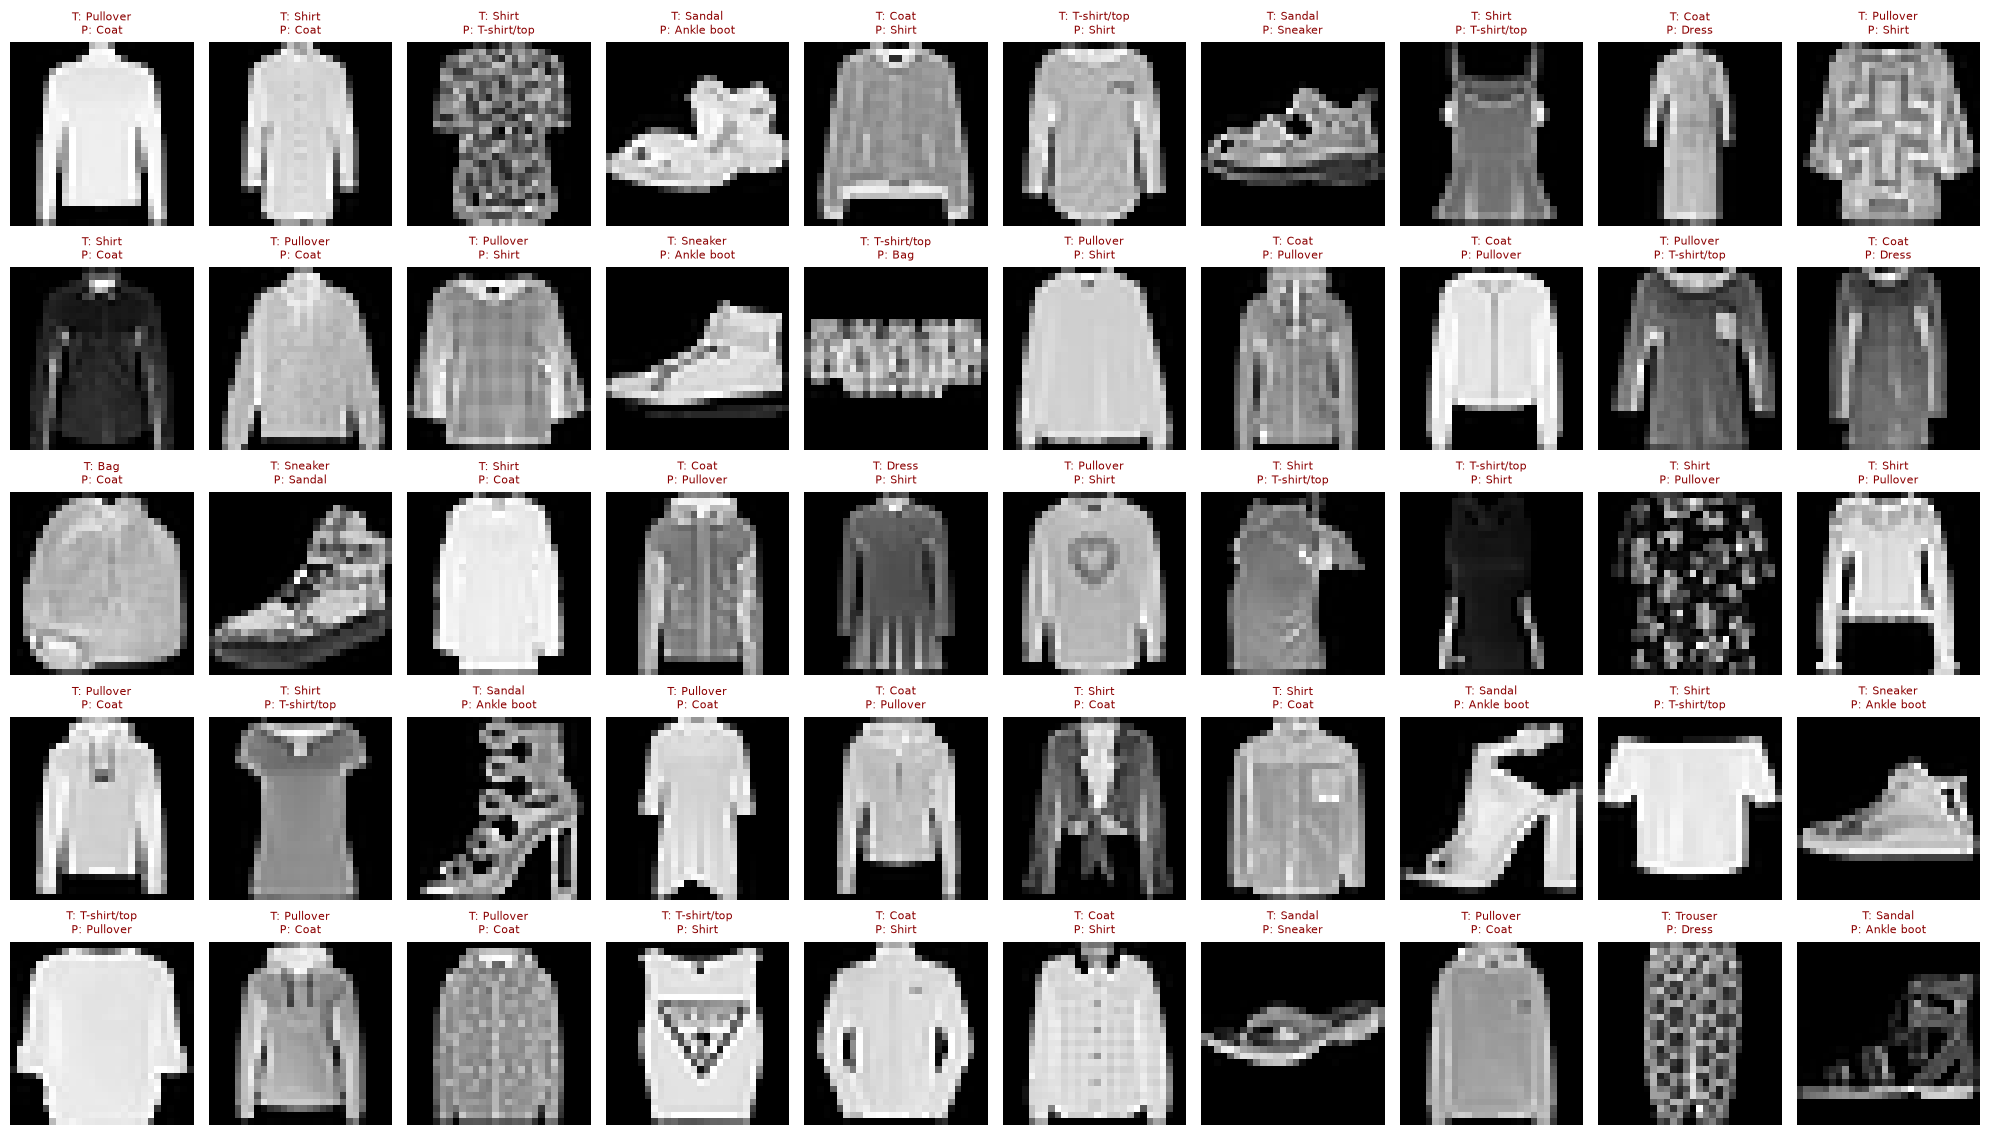

In [42]:
fig, axes = plt.subplots(5, 10, figsize=(20, 11.5))
for ax, idx in zip(axes.ravel(), chosen):
    ax.imshow(val_images[idx], cmap="gray")
    ax.set_title("T: %s\nP: %s" % (class_names[y_true[idx]], class_names[y_pred[idx]]), fontsize=8, color="darkred")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Шаг A. Какие пары классов путаются чаще всего?

Смотрим на **все** ошибки модели (а не только на 50) — так категории будут опираться на реальную картину, а не на случайную выборку.

In [43]:
pair_counts = pd.Series([tuple(sorted((class_names[t], class_names[p]))) for t, p in zip(y_true[error_indices], y_pred[error_indices])])
top_pairs = pair_counts.value_counts().head(10)
confusion = pd.crosstab(pd.Series(y_true, name="true"), pd.Series(y_pred, name="predicted"))
confusion.index = class_names
confusion.columns = class_names

print("Top confused pairs among ALL %d validation errors:" % len(error_indices))
print(top_pairs.to_string())
print("\nShare of all errors made by the top 3 pairs: %.0f%%" % (100 * top_pairs.head(3).sum() / len(error_indices)))
print("\nPer-class error rate:")
per_class_error = pd.Series({class_names[c]: (y_pred[y_true == c] != c).mean() for c in range(10)}).sort_values(ascending=False)
print(per_class_error.round(3).to_string())

Top confused pairs among ALL 1135 validation errors:
(Shirt, T-shirt/top)       214
(Coat, Pullover)           184
(Pullover, Shirt)          139
(Coat, Shirt)              138
(Ankle boot, Sneaker)       81
(Coat, Dress)               63
(Sandal, Sneaker)           47
(Dress, Shirt)              47
(Dress, T-shirt/top)        47
(Pullover, T-shirt/top)     29

Share of all errors made by the top 3 pairs: 47%

Per-class error rate:
Shirt          0.362
Pullover       0.223
T-shirt/top    0.127
Coat           0.120
Dress          0.088
Sandal         0.065
Sneaker        0.062
Ankle boot     0.030
Trouser        0.029
Bag            0.029


### Что показали пары и классы → откуда берутся категории

1. Модель ошиблась на **1135 из 10 000** картинок (11,35 %).
2. Ошибки **сильно сосредоточены**. Три самые частые пары — Shirt↔T-shirt (214), Coat↔Pullover (184), Pullover↔Shirt (139) — дают **47 % всех ошибок**.
3. По классам: **Shirt ошибается в 36,2 % случаев** (втрое чаще среднего), Pullover — в 22,3 %. А Trouser, Bag и Ankle boot — около 3 %. Проблема не «везде понемногу», а в одной семье: **верхняя одежда с похожим силуэтом** (футболка, рубашка, пуловер, пальто).
4. Отдельно выделяется обувь: Ankle boot↔Sneaker (81) и Sandal↔Sneaker (47).

**Из этого списка мы и берём категории** (не придумываем заранее):

| Категория | Какие пары входят |
|---|---|
| Shirt vs T-shirt | Shirt↔T-shirt |
| Pullover vs Coat | Pullover↔Coat |
| Shirt vs Pullover/Coat | Shirt↔Pullover, Shirt↔Coat |
| Footwear confusion | Sandal, Sneaker, Ankle boot между собой |
| Dress vs tops/coats | Dress с футболкой, пуловером, пальто, рубашкой |
| Other | всё остальное (редкие пары, например Pullover↔T-shirt — 29 из 1135) |

### Шаг B. Второй вид категорий — качество картинки

Andrew Ng советует искать ошибки не только по «что с чем перепутали», но и по **свойствам картинки** (размытая, тёмная и т. п.). Мы не будем решать «размытая или нет» на глаз, а **измерим**:

- **резкость** = средний перепад яркости между соседними пикселями (чем меньше, тем «мыльнее» картинка);
- **яркость** = средняя яркость пикселей (маленькая — тёмный/маленький предмет).

Флаг «низкая детализация» ставим тем картинкам, чья резкость ниже 25-го процентиля по всей validation-выборке; «тёмная» — тем, у кого яркость ниже 25-го процентиля.

А затем **проверяем, имеют ли эти флаги вообще значение**: правда ли, что на таких картинках ошибок больше? Если нет — категория не имеет смысла.

In [44]:
imgs = val_images / 255.0
sharpness = (np.abs(np.diff(imgs, axis=1)).mean(axis=(1, 2)) + np.abs(np.diff(imgs, axis=2)).mean(axis=(1, 2))) / 2
brightness = imgs.mean(axis=(1, 2))

low_detail = sharpness < np.percentile(sharpness, 25)
dark = brightness < np.percentile(brightness, 25)
is_error = (y_pred != y_true)

flag_check = pd.DataFrame({
    "images": [low_detail.sum(), (~low_detail).sum(), dark.sum(), (~dark).sum()],
    "error rate, %": [100 * is_error[low_detail].mean(), 100 * is_error[~low_detail].mean(),
                      100 * is_error[dark].mean(), 100 * is_error[~dark].mean()],
}, index=["low detail", "normal detail", "dark / small item", "normal brightness"]).round(2)
print(flag_check)

                   images  error rate, %
low detail           2500           8.80
normal detail        7500          12.20
dark / small item    2500           7.32
normal brightness    7500          12.69


Результат неожиданный: **на «тёмных» и «мыльных» картинках ошибок меньше, а не больше**. Прежде чем объяснять, проверим, из каких классов состоят эти группы и как у этих классов обстоят дела с ошибками.

In [45]:
per_class = pd.DataFrame({
    "mean brightness": [brightness[y_true == c].mean() for c in range(10)],
    "mean sharpness": [sharpness[y_true == c].mean() for c in range(10)],
    "share of class in dark group, %": [100 * dark[y_true == c].mean() for c in range(10)],
    "error rate, %": [100 * is_error[y_true == c].mean() for c in range(10)],
}, index=class_names).round(3)

footwear = np.isin(y_true, [5, 7])
share_footwear_in_dark = 100 * footwear[dark].mean()
corr_bright = np.corrcoef(per_class["error rate, %"], per_class["mean brightness"])[0, 1]
corr_sharp = np.corrcoef(per_class["error rate, %"], per_class["mean sharpness"])[0, 1]

In [46]:
print(per_class.sort_values("error rate, %", ascending=False))
print("\nShare of the dark group made of Sandals and Sneakers: %.0f%%" % share_footwear_in_dark)
print("correlation between class error rate and class brightness: %.2f" % corr_bright)
print("correlation between class error rate and class sharpness : %.2f" % corr_sharp)

             mean brightness  mean sharpness  share of class in dark group, %  error rate, %
Shirt                  0.333           0.086                             15.1           36.2
Pullover               0.374           0.091                              8.4           22.3
T-shirt/top            0.328           0.074                             13.4           12.7
Coat                   0.391           0.087                              5.7           12.0
Dress                  0.260           0.071                             21.0            8.8
Sandal                 0.136           0.075                             81.9            6.5
Sneaker                0.169           0.063                             67.6            6.2
Ankle boot             0.300           0.077                              4.7            3.0
Trouser                0.223           0.071                             25.1            2.9
Bag                    0.353           0.085                          

### Что показала проверка флагов

| Группа | Доля ошибок |
|---|---|
| низкая детализация | **8,8 %** |
| обычная детализация | 12,2 % |
| тёмные / маленькие предметы | **7,3 %** |
| обычная яркость | 12,7 % |

**Гипотеза «ошибки из-за размытых и тёмных картинок» не подтвердилась — результат обратный:** на таких картинках модель ошибается **реже**.

**Почему так.** Таблица по классам показывает причину: «тёмная» группа почти на 60 % состоит из сандалий и кроссовок — это лёгкие для модели классы (ошибка 6,5 % и 6,2 %). А самые сложные классы — Shirt, Pullover, T-shirt, Coat — это **крупные яркие предметы**: они занимают много места в кадре, поэтому и средняя яркость, и резкость у них выше. Между классами ошибка и яркость/резкость коррелируют положительно (0,42 и 0,54), то есть флаги просто «замаскированы» под класс. (Оговорка: корреляция посчитана по 10 точкам — это подсказка, а не строгое доказательство.)

**Вывод:** качество изображения — **не причина** ошибок, и строка «Blurry outlines», которую приводит задание как пример, в наших данных не подтверждается. Флаги оставляем в таблице как проверенную и отвергнутую гипотезу, а категории для исправления берём только из путаницы классов.

### Шаг C. Таблица ошибок (Error Analysis Table)

Каждой из 50 ошибок ставим: категорию «путаница» (одну) и два флага качества картинки (можно оба сразу). Категории взяты из шага A.

In [47]:
def confusion_bucket(true_class, pred_class):
    pair = {true_class, pred_class}
    if pair == {0, 6}:
        return "Shirt vs T-shirt"
    if pair == {2, 4}:
        return "Pullover vs Coat"
    if pair <= {2, 4, 6}:
        return "Shirt vs Pullover/Coat"
    if 3 in pair and (pair - {3}) <= {0, 2, 4, 6}:
        return "Dress vs tops/coats"
    if pair <= {5, 7, 9}:
        return "Footwear confusion"
    return "Other"


error_table = pd.DataFrame({
    "image index": chosen,
    "true": [class_names[y_true[i]] for i in chosen],
    "predicted": [class_names[y_pred[i]] for i in chosen],
    "bucket": [confusion_bucket(y_true[i], y_pred[i]) for i in chosen],
    "low detail": ["x" if low_detail[i] else "" for i in chosen],
    "dark / small": ["x" if dark[i] else "" for i in chosen],
})
error_table.index = range(1, 51)

all_errors_bucket = pd.Series([confusion_bucket(y_true[i], y_pred[i]) for i in error_indices]).value_counts()

bucket_summary = error_table["bucket"].value_counts().rename("errors of 50").to_frame()
bucket_summary["share of errors, %"] = (100 * bucket_summary["errors of 50"] / 50).round(1)
bucket_summary["share among ALL errors, %"] = (100 * all_errors_bucket / len(error_indices)).round(1)
bucket_summary["val error if bucket fixed, %"] = (100 * val_error * (1 - bucket_summary["errors of 50"] / 50)).round(2)
quality_summary = pd.DataFrame({
    "errors of 50": [(error_table["low detail"] == "x").sum(), (error_table["dark / small"] == "x").sum()]},
    index=["flag: low detail", "flag: dark / small"])
quality_summary["share of errors, %"] = (100 * quality_summary["errors of 50"] / 50).round(1)

assert bucket_summary["errors of 50"].sum() == 50

In [48]:
print(error_table.to_string())
print("\nBuckets (every error belongs to exactly one):")
print(bucket_summary)
print("\nQuality flags (an error can have both):")
print(quality_summary)
print("\ncurrent validation error: %.2f%%" % (100 * val_error))

    image index         true    predicted                  bucket low detail dark / small
1           255     Pullover         Coat        Pullover vs Coat                        
2           444        Shirt         Coat  Shirt vs Pullover/Coat                        
3           563        Shirt  T-shirt/top        Shirt vs T-shirt                        
4           898       Sandal   Ankle boot      Footwear confusion                        
5           905         Coat        Shirt  Shirt vs Pullover/Coat                        
6           965  T-shirt/top        Shirt        Shirt vs T-shirt                        
7           993       Sandal      Sneaker      Footwear confusion                       x
8          1129        Shirt  T-shirt/top        Shirt vs T-shirt          x             
9          1160         Coat        Dress     Dress vs tops/coats                        
10         1533     Pullover        Shirt  Shirt vs Pullover/Coat                        
11        

### Как читать таблицу

1. **Выборка репрезентативна.** Доли категорий в 50 случайных ошибках близки к долям среди всех 1135 ошибок: Shirt vs Pullover/Coat — 28,0 % против 24,4 %, Pullover vs Coat — 22,0 % против 16,2 %, Footwear — 18,0 % против 13,6 %, Shirt vs T-shirt — 16,0 % против 18,9 %. Самое большое расхождение — Dress vs tops/coats: 6,0 % против 15,3 %; это ожидаемо при выборке из 50 (погрешность порядка ±6 п.п.). Поэтому для итоговых выводов опираемся в первую очередь на колонку «share among ALL errors».
2. **Три категории про верхнюю одежду** (Shirt vs Pullover/Coat, Pullover vs Coat, Shirt vs T-shirt) дают 33 из 50 ошибок (66 %) в выборке и **59,5 % среди всех ошибок**. Это главное место, где можно выиграть.
3. **Потолок выигрыша (по методике Ng).** Колонка «val error if bucket fixed» показывает, какой стала бы ошибка, если бы категория полностью исчезла: например, для Shirt vs Pullover/Coat — **8,17 %** вместо 11,35 %. Это верхняя граница по выборке, реальный выигрыш будет меньше.
4. **Флаги качества** встречаются среди ошибок реже (18 % и 12 %), чем среди всех картинок (по 25 %), что согласуется с проверкой выше: это не причина ошибок.

## 4.2 Bias / Variance — диагностика

По Andrew Ng, ответить на вопрос «что улучшать» помогают три числа:

| Что | Как считаем |
|---|---|
| Train error | ошибка на обучающей выборке, **в режиме eval** (dropout выключен), иначе оценка занижена |
| Dev (Val) error | ошибка на валидации |
| Оптимальная ошибка | к чему стремимся (у человека на такой задаче маленькая) |

- **Avoidable bias** = Train error − оптимальная ошибка → если большая, модели не хватает «ума» (High Bias).
- **Variance** = Val error − Train error → если большая, модель переобучена (High Variance).

In [49]:
y_train_true, y_train_pred = predict_all(final_model, X_train_t, y_train_t)

train_error = (y_train_pred != y_train_true).mean()
variance_gap = val_error - train_error

assumed_optimal = {"0% (strict)": 0.00, "3%": 0.03, "5%": 0.05}
bias_table = pd.DataFrame({
    name: {"train error, %": 100 * train_error, "val error, %": 100 * val_error,
           "avoidable bias, %": 100 * (train_error - opt), "variance (val - train), %": 100 * variance_gap}
    for name, opt in assumed_optimal.items()}).T.round(2)

assert 0 < train_error < val_error
print("FINAL TRAIN ERROR (eval mode): %.2f%%" % (100 * train_error))
print("FINAL DEV (VAL) ERROR        : %.2f%%" % (100 * val_error))
print("\nThe 'optimal' error is an ASSUMPTION (we did not measure human error), so we try three values:")
print(bias_table)

FINAL TRAIN ERROR (eval mode): 8.33%
FINAL DEV (VAL) ERROR        : 11.35%

The 'optimal' error is an ASSUMPTION (we did not measure human error), so we try three values:
             train error, %  val error, %  avoidable bias, %  variance (val - train), %
0% (strict)            8.33         11.35               8.33                       3.02
3%                     8.33         11.35               5.32                       3.02
5%                     8.33         11.35               3.32                       3.02


### Чтение результата

- **Train error 8,33 %** (измерен в режиме eval — без dropout; поэтому он ниже, чем «train acc» из таблицы части 3, где dropout включён и ошибка 10,5 %). **Val error 11,35 %.**
- **Variance** (разрыв) = **3,02 п.п.** Это умеренно.
- **Avoidable bias** зависит от того, какую ошибку считать оптимальной. Мы её не измеряли, поэтому честно перебрали три значения: 0 %, 3 %, 5 % → bias 8,33 / 5,32 / 3,32 п.п.
- **Когда bias больше variance?** Они равны при оптимальной ошибке $8{,}33 - 3{,}02 = 5{,}31\ \%$. Для любой оптимальной ошибки **ниже 5,3 %** главная проблема — **bias** (модели не хватает качества на самих обучающих данных), а variance — вторая по величине. Для такой простой задачи, как Fashion-MNIST, считать ошибку человека выше 5 % трудно, поэтому диагноз «в первую очередь High Bias» устойчив к нашему допущению.
- Это гипотеза, и мы сразу проверяем её экспериментами (таблица ниже) — по правилу Ng: если проблема в bias, помогает рычаг, снижающий bias, и не помогает регуляризация.

### Проверяем предложения экспериментами, а не мнением

Чтобы три рекомендации не были «просто идеями», проверим на практике по одному способу из каждой группы (все — с AdamW, 10 эпох, то же зерно). Для честного сравнения train error для всех измеряем одинаково — в режиме eval.

| Эксперимент | Что меняем | Что проверяем |
|---|---|---|
| A. Больше ёмкость | слои `512 → 256` вместо `256 → 128` | снижает ли это train error (лечит bias)? |
| B. Сильнее регуляризация | dropout 0.5 и weight decay 0.1 | уменьшается ли разрыв train–val (лечит variance)? |
| C. Аугментация | случайные отражения и сдвиги картинок | улучшает ли это val error? |
| D. Слабее регуляризация | dropout 0.1 и weight decay 0.001 | а может, регуляризации сейчас слишком много? |
| E. Ёмкость + время | сеть `512 → 256` и 20 эпох вместо 10 | помогает ли больше ёмкости при более долгом обучении? |

Аугментацию («дополнение» данных) делаем простой функцией над батчем: каждую картинку с вероятностью 1/2 отражаем по горизонтали и сдвигаем на 0…2 пикселя в случайную сторону (фон при сдвиге заполняем «чёрным» = −1). Сначала проверяем, что функция ничего не ломает.

augmentation keeps the shape and the value range; 98% of the images actually changed


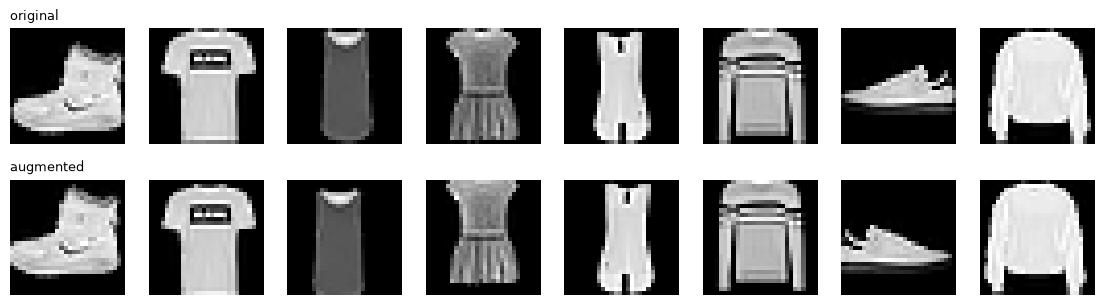

In [50]:
def augment_batch(images):
    images = images.clone()
    flip = torch.rand(images.shape[0]) < 0.5
    images[flip] = images[flip].flip(-1)
    padded = F.pad(images, (2, 2, 2, 2), value=-1.0)
    shifts = torch.randint(0, 5, (images.shape[0], 2))
    result = torch.empty_like(images)
    for i in range(images.shape[0]):
        dy, dx = int(shifts[i, 0]), int(shifts[i, 1])
        result[i] = padded[i, :, dy:dy + 28, dx:dx + 28]
    return result


set_seed()
sample = X_train_t[:256]
sample_aug = augment_batch(sample)
share_changed = (sample_aug != sample).flatten(1).any(dim=1).float().mean().item()
assert sample_aug.shape == sample.shape
assert sample_aug.min() >= -1.0 and sample_aug.max() <= 1.0
assert 0.5 < share_changed <= 1.0
print("augmentation keeps the shape and the value range; %.0f%% of the images actually changed" % (100 * share_changed))

fig, axes = plt.subplots(2, 8, figsize=(14, 3.6))
for k in range(8):
    axes[0, k].imshow(sample[k, 0], cmap="gray"); axes[0, k].axis("off")
    axes[1, k].imshow(sample_aug[k, 0], cmap="gray"); axes[1, k].axis("off")
axes[0, 0].set_title("original", fontsize=9, loc="left"); axes[1, 0].set_title("augmented", fontsize=9, loc="left")
plt.show()

In [51]:
def evaluate_errors(model):
    yt, yp = predict_all(model, X_train_t, y_train_t)
    vt, vp = predict_all(model, X_val_t, y_val_t)
    return (yp != yt).mean(), (vp != vt).mean()


def experiment(hidden=(256, 128), p_drop=0.3, weight_decay=1e-2, augment=None, epochs=EPOCHS):
    set_seed()
    model = Net(hidden=hidden, p_drop=p_drop)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    train_model(model, optimizer, epochs, augment=augment)
    return evaluate_errors(model)


train_err_base, val_err_base = evaluate_errors(final_model)
results = {"baseline (256-128, drop 0.3, wd 0.01)": (train_err_base, val_err_base)}
for name, kwargs in [("A. bigger network (512-256)", dict(hidden=(512, 256))),
                     ("B. stronger regularization (drop 0.5, wd 0.1)", dict(p_drop=0.5, weight_decay=0.1)),
                     ("C. data augmentation (flip + shift)", dict(augment=augment_batch)),
                     ("D. weaker regularization (drop 0.1, wd 0.001)", dict(p_drop=0.1, weight_decay=0.001)),
                     ("E. bigger network + longer (512-256, 20 epochs)", dict(hidden=(512, 256), epochs=20))]:
    start_time = time.time()
    results[name] = experiment(**kwargs)
    print("%-48s done in %3.0f s" % (name, time.time() - start_time))

A. bigger network (512-256)                      done in  66 s


B. stronger regularization (drop 0.5, wd 0.1)    done in  44 s


C. data augmentation (flip + shift)              done in  72 s


D. weaker regularization (drop 0.1, wd 0.001)    done in  44 s


E. bigger network + longer (512-256, 20 epochs)  done in 131 s


In [52]:
experiments = pd.DataFrame(results, index=["train error", "val error"]).T * 100
experiments["gap (val - train)"] = experiments["val error"] - experiments["train error"]
experiments["val error change vs baseline"] = experiments["val error"] - experiments.loc[experiments.index[0], "val error"]
print(experiments.round(2))

                                                 train error  val error  gap (val - train)  val error change vs baseline
baseline (256-128, drop 0.3, wd 0.01)                   8.33      11.35               3.02                          0.00
A. bigger network (512-256)                             7.52      11.21               3.70                         -0.14
B. stronger regularization (drop 0.5, wd 0.1)          10.38      12.53               2.15                          1.18
C. data augmentation (flip + shift)                    13.44      14.65               1.21                          3.30
D. weaker regularization (drop 0.1, wd 0.001)           7.19      11.50               4.31                          0.15
E. bigger network + longer (512-256, 20 epochs)         5.09      10.39               5.30                         -0.96


### Что показали эксперименты

Погрешность оценки val error на 10 000 картинок: $\sqrt{0{,}11 \cdot 0{,}89 / 10000} \approx 0{,}3$ п.п. Всё, что меняется меньше чем на 0,3 п.п., — шум.

| Эксперимент | train error | val error | Что произошло |
|---|---|---|---|
| A. Сеть побольше | 8,33 → 7,52 | 11,35 → 11,21 (−0,14) | bias чуть упал, но разрыв вырос (3,02 → 3,70). Выигрыш в пределах шума |
| B. Регуляризация сильнее | 8,33 → 10,38 | 11,35 → **12,53 (+1,18)** | разрыв уменьшился (2,15), но train error вырос больше — стало **хуже** |
| C. Аугментация (отражение + сдвиг) | 8,33 → **13,44** | 11,35 → **14,65 (+3,30)** | разрыв минимальный (1,21), но модель за 10 эпох не успевает выучить усложнённые данные — **недообучение** |
| D. Регуляризация слабее | 8,33 → 7,19 | 11,35 → 11,50 (+0,15) | train error упал, но разрыв вырос до 4,31 и val error не улучшился — в пределах шума. Текущая регуляризация примерно на «золотой середине» |
| E. Сеть побольше + 20 эпох | 8,33 → **5,09** | 11,35 → **10,39 (−0,96)** | **лучший результат**: bias сильно уменьшился. Разрыв вырос до 5,30 п.п. — теперь на очереди variance |

**Вывод.** Диагноз подтверждается: помогает то, что **снижает bias** (больше ёмкости и больше времени обучения — эксперимент E), а то, что усиливает регуляризацию (B, C), **вредит**, потому что регуляризовать сети, которая и без того недообучена, бессмысленно. Улучшения A и D лежат в пределах погрешности, а вот E (−0,96 п.п.), B (+1,18) и C (+3,30) — вне её, и им можно доверять.

### Engineering summary (10–15 sentences)



1. The final AdamW network (784-256-128-10 with BatchNorm and Dropout 0.3) reaches a train error of 8.33% and a validation error of 11.35% after 10 epochs.
2. The gap between them (variance) is 3.02 percentage points, while the avoidable bias is between 3.3 and 8.3 points, depending on whether the optimal error is assumed to be 5% or 0%.
3. We did not measure human error, so we checked how the diagnosis depends on it: bias is larger than variance for any optimal error below 5.3%.
4. The experiments agree with this diagnosis: the bigger network trained for 20 epochs (E) cut the train error to 5.09% and the validation error to 10.39%.
5. More regularization made the model worse (stronger dropout and weight decay: +1.18 points; flip and shift augmentation: +3.30 points), which shows that the model is not heavily overfitted.
6. Weaker regularization (D) lowered the train error to 7.19% but left the validation error unchanged within noise (11.50%), so the current dropout and weight decay are close to a sensible balance.
7. The errors are concentrated: three upper-body confusions (Shirt vs T-shirt, Pullover vs Coat, Shirt vs Pullover/Coat) cause 59.5% of all 1,135 validation errors, and the class Shirt alone has a 36.2% error rate.
8. In the random sample of 50 errors the largest bucket is Shirt vs Pullover/Coat (28%), and fixing it completely would lower the validation error from 11.35% to about 8.2%.
9. Image quality is not the problem: dark and low-detail images have lower error rates (7.3% and 8.8%) than the rest (12.7% and 12.2%), because these groups consist mostly of easy footwear classes.
10. Our primary diagnosis is therefore high avoidable bias with a moderate variance, concentrated in visually similar clothing classes.
11. The first action is to increase the capacity and the training time, and then to bring moderate regularization back, because the gap grows to 5.3 points.
12. The second action is to target the confusable upper-body classes with more labelled examples, class weights or a convolutional architecture.
13. The third action is to postpone heavy augmentation and stronger regularization until the model fits the training set better, because at the current capacity they increase the error.

*По-русски, коротко: у модели в основном high bias (не хватает ёмкости и времени обучения), variance умеренный; ошибки сосредоточены на рубашках/пуловерах/пальто/футболках, а не на «плохих» картинках; сильнее регуляризовать сейчас не надо.*

### Три конкретных действия (по методике Andrew Ng) и чем каждое подкреплено

| № | Действие | Чем подкреплено в этом ноутбуке | Что проверить дальше |
|---|---|---|---|
| 1 | **Увеличить ёмкость и время обучения** (сеть `512→256`, 20 и больше эпох, затем расписание шага обучения), после этого вернуть **умеренную** регуляризацию | Эксперимент E: train error 8,33 → 5,09 %, val error 11,35 → 10,39 % (−0,96 п.п., больше погрешности 0,3). Но разрыв вырос до 5,3 п.п. — на следующем шаге bias уже не главный | Подобрать dropout 0,2–0,3 и weight decay для новой, большей сети; смотреть, уменьшается ли разрыв без роста train error |
| 2 | **Бить по главной семье ошибок**: больше размеченных примеров Shirt, T-shirt, Pullover, Coat; взвешивание классов в функции потерь; свёрточная сеть (видит воротник, рукава, пуговицы) | Три «верхних» категории дают **59,5 %** всех ошибок; Shirt ошибается в 36,2 % случаев; полное исправление категории Shirt vs Pullover/Coat снизило бы val error до ≈ 8,2 % (оценка по выборке 50) | Свёрточная сеть — **гипотеза, мы её не проверяли**; сравнить val error и ошибку на классе Shirt |
| 3 | **Пока не усиливать регуляризацию и не включать сильную аугментацию**; не тратить время на «улучшение качества картинок» | Эксперимент B: val error +1,18 п.п.; C: +3,30 п.п. (train error 13,4 % — модель недообучена); флаги «тёмная/размытая» ошибок не объясняют (7–9 % против 12–13 %) | Вернуться к аугментации, когда сеть станет больше и обучение дольше (она увеличивает train error в первую очередь) |

Порядок важен: сначала снижаем **bias** (действие 1), потому что именно он сейчас главный; потом, если разрыв train−val станет основной проблемой, подключаем регуляризацию и аугментацию; параллельно целимся в самую проблемную семью классов (действие 2).

---
# Итог: что где выполнено

| Часть | Требование | Где в ноутбуке | Чем доказано |
|---|---|---|---|
| 1 | He и Xavier инициализация | 1.1 | тест std + эксперимент с 10 слоями |
| 1 | ReLU, Sigmoid, Softmax (прямой и обратный проход) | 1.2 | значения + численный градиент |
| 1 | Linear, backward для L слоёв, Cross-Entropy | 1.3 | тесты + Gradient Check |
| 2 | SGD+Momentum, RMSprop, Adam | 2.1 | ручной расчёт + «овраг» |
| 2 | L2 и Inverted Dropout | 2.2 | тесты + Gradient Check с L2 и dropout |
| 2 | Всё вместе на реальных данных | 2.3 | обучение NumPy-сети |
| 3 | PyTorch-модель и цикл обучения | 3.1 | тест воспроизводимости |
| 3 | SGD vs SGD+Momentum vs AdamW, графики, анализ | 3.2 | кривые, таблица, проверка честности |
| 4 | 50 ошибок, таблица категорий | 4.1 | выбор категорий по данным + проверка флагов |
| 4 | Bias/Variance, 3 рекомендации | 4.2 | три эксперимента |

Зёрна заданы в начале (`SEED = 42`). Перед сдачей: **Runtime → Restart and run all**.